<a href="https://colab.research.google.com/github/notrainaarora/rug-pull-radar/blob/main/rug_pull_radar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rug-Pull Radar 🛡️
### Part of the Crypto Safety Copilot · AI + Finance track · Veritas AI High School Hackathon 2026

**Rug-Pull Radar helps a first-time crypto buyer by taking a brand-new token and giving back a scam-risk score with the top reasons behind it, using only what is visible in the token's first hour.**

> **This project is a prototype and is not financial advice.**

**How to use this notebook:** run the cells from top to bottom (Runtime → Run all). Every code cell has a text cell above it explaining what it does and why.

| Part | What happens |
|---|---|
| 1 | Setup and loading the labeled data |
| 2 | Exploring the data (when do rug pulls happen?) |
| 3 | The leakage trap: why a 99% score would be a lie |
| 4 | Launch-time features and a split by time |
| 5 | Baselines: the simple rules we must beat |
| 6 | First model and honest results |
| 7 | *(Saturday)* Rebuilding features at a fixed one-hour cutoff with Etherscan |

## Part 1 · Setup and data

**What this does:** Installs the libraries we use and connects Google Drive, so the dataset is saved there and doesn't have to be downloaded again if Colab disconnects. If Drive permission is refused, it carries on with Colab's temporary storage.

**Why:** Free Colab wipes its files when it disconnects. Keeping data in Drive makes the notebook restartable.

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !pip -q install xgboost shap gradio
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA_DIR = '/content/drive/MyDrive/rugpull_radar'
    except Exception as e:
        # Drive permission wasn't granted: keep going with Colab's temporary disk instead
        print('Google Drive not connected (', e, '). Using temporary storage; data re-downloads if Colab disconnects.')
        DATA_DIR = '/content/data'
else:
    DATA_DIR = './data'
os.makedirs(DATA_DIR, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 60)
print('Ready. Data folder:', DATA_DIR)

Mounted at /content/drive
Ready. Data folder: /content/drive/MyDrive/rugpull_radar


**What this does:** Downloads the labeled dataset (one CSV file, about 13 MB) from the public GitHub repository of the RugPull-Prediction-AI project, unless it's already in Drive.

**Why:** We need tokens that researchers already labeled as rug pull or not. Building labels ourselves would take the whole weekend.

In [2]:
URL = ('https://raw.githubusercontent.com/kangmyoungseok/RugPull-Prediction-AI/main/'
       '2.%20Feature/4.%20Labeling%20File/Labeling_v3.3.csv')
path = os.path.join(DATA_DIR, 'uniswap_rugpull_labels.csv')
if not os.path.exists(path):
    raw = pd.read_csv(URL, low_memory=False)
    raw.to_csv(path, index=False)
raw = pd.read_csv(path, low_memory=False)
print(raw.shape[0], 'tokens,', raw.shape[1], 'columns')

18344 tokens, 56 columns


**What this does:** Shows how many tokens are rug pulls, and prints a few rows so we can look at real examples with our own eyes.

**Why:** The Hacker Guide says to look at the data before training anything. It's the easiest way to spot problems.

In [3]:
raw['created'] = pd.to_datetime(raw['createdAtTimestamp'])
raw['is_rug'] = raw['is_rugpull'].astype(int)
raw = raw.sort_values('created').reset_index(drop=True)

print(raw['is_rug'].value_counts().rename({1: 'rug pull', 0: 'not rug pull'}))
print(f"Rug-pull share: {raw['is_rug'].mean():.1%}")
print('Launch dates from', raw['created'].min().date(), 'to', raw['created'].max().date())
raw[['token00.name', 'token00.symbol', 'created', 'initial_Liquidity_Eth', 'is_rug', 'rugpull_method']].sample(10, random_state=1)

is_rug
rug pull        16507
not rug pull     1837
Name: count, dtype: int64
Rug-pull share: 90.0%
Launch dates from 2020-10-01 to 2021-11-14


,token00.name,token00.symbol,created,initial_Liquidity_Eth,is_rug,rugpull_method
6388,Alchemy,ALCH,2021-03-27,0.1,0,NaN
3983,Jess Network,JESS,2020-11-28,20.0,1,burn
13682,WTHE TRUTH,wUFO,2021-07-05,10.0,1,burn
5367,Poolz.Finance,POOLZ,2021-01-15,200.0,1,burn
8246,Mercurial Finance,MER,2021-05-13,150.0,1,burn
5781,Umbrella,UMB,2021-02-09,30.0,1,burn
3278,nocredittoken.com,NOCREDIT,2020-11-13,3.5,1,burn
18023,Ulquiorra,ULQUIORRA,2021-11-07,1.5,1,burn
16545,Genos Inu,Genos,2021-09-30,2.0,1,burn
153,unilend.finance,UFT,2020-10-03,120.0,1,burn


## Part 2 · Exploring the data

**What this does:** Measures how long after launch each rug pull happened, and draws it as a chart.

**Why:** This decides *when* our tool can help. If scams happen fast, a tool that waits a day is useless.

25% of rug pulls happen within 0.9 hours of launch
50% within 5.9 hours
75% within 24.5 hours
Share of rug pulls within the first hour: 26%


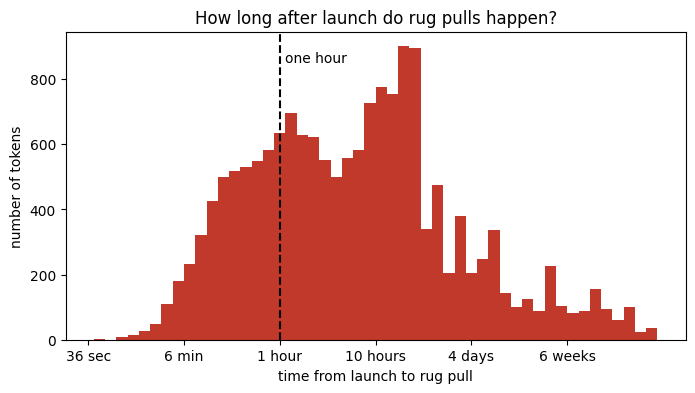

In [4]:
rugs = raw[raw['is_rug'] == 1].copy()
rugs['hours_to_rug'] = rugs['rugpull_proceeding_hour'].str.rstrip('h').astype(float)
q = rugs['hours_to_rug'].quantile([0.25, 0.5, 0.75])
print(f"25% of rug pulls happen within {q[0.25]:.1f} hours of launch")
print(f"50% within {q[0.5]:.1f} hours")
print(f"75% within {q[0.75]:.1f} hours")
print(f"Share of rug pulls within the first hour: {(rugs['hours_to_rug'] < 1).mean():.0%}")

plt.figure(figsize=(8, 4))
plt.hist(np.log10(rugs['hours_to_rug'].clip(lower=0.01)), bins=50, color='#c0392b')
plt.xticks([-2, -1, 0, 1, 2, 3], ['36 sec', '6 min', '1 hour', '10 hours', '4 days', '6 weeks'])
plt.axvline(0, color='black', linestyle='--'); plt.text(0.05, plt.ylim()[1]*0.9, 'one hour')
plt.title('How long after launch do rug pulls happen?'); plt.xlabel('time from launch to rug pull'); plt.ylabel('number of tokens')
plt.show()

**What this does:** Charts the share of rug pulls in each quarter-year.

**Why:** We'll train on older tokens and test on newer ones, so we need to know whether the scam rate changes over time.

         tokens  rug share
created                   
2020Q4     5060      0.934
2021Q1     1450      0.880
2021Q2     6660      0.907
2021Q3     3381      0.883
2021Q4     1793      0.825


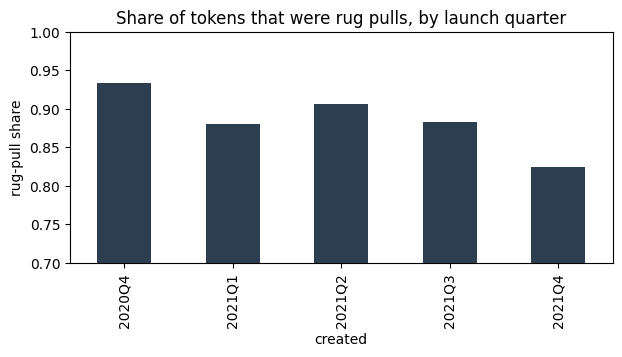

In [5]:
by_q = raw.groupby(raw['created'].dt.to_period('Q'))['is_rug'].agg(['count', 'mean'])
print(by_q.rename(columns={'count': 'tokens', 'mean': 'rug share'}).round(3))
by_q['mean'].plot(kind='bar', color='#2c3e50', figsize=(7, 3), title='Share of tokens that were rug pulls, by launch quarter')
plt.ylim(0.7, 1); plt.ylabel('rug-pull share'); plt.show()

## Part 3 · The leakage trap

**What this does:** Trains a quick model on the dataset's ready-made trading features and shows it scores almost perfectly.

**Why:** For scams, those features were measured right up to the moment of the rug pull; for normal tokens, over a full day. So the *length of the window itself* gives the answer away. This is called leakage, and it's the most common way AI projects fool themselves.

In [6]:
from sklearn.metrics import average_precision_score
import xgboost as xgb

n = len(raw); train_end, val_end = int(n * 0.70), int(n * 0.85)
leaky_cols = ['active_period', 'swap_count', 'mint_count', 'burn_count']
L = raw[leaky_cols].apply(pd.to_numeric, errors='coerce').fillna(0)
leaky = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05)
leaky.fit(L.iloc[:train_end], raw['is_rug'].iloc[:train_end])
p = leaky.predict_proba(L.iloc[val_end:])[:, 1]
print('Leaky model PR-AUC on newest tokens:', round(average_precision_score(raw['is_rug'].iloc[val_end:], p), 3))
window_hours = pd.to_numeric(raw['active_period'], errors='coerce') / 3600
print('Median feature window: rug pulls', round(window_hours[raw.is_rug == 1].median(), 1), 'hours,',
      'normal tokens', round(window_hours[raw.is_rug == 0].median(), 1), 'hours')
print('-> Too good to be true. We throw these features away.')

Leaky model PR-AUC on newest tokens: 0.99
Median feature window: rug pulls 1.5 hours, normal tokens 1446.5 hours
-> Too good to be true. We throw these features away.


## Part 4 · Launch-time features and a split by time

**What this does:** Builds 8 features that anyone could see at the moment a token launches.

**Why:** These can't leak, because they're fixed before any trading happens. On Saturday we add first-hour trading features rebuilt the same way for every token.

In [7]:
name = raw['token00.name'].fillna('').astype(str)
symbol = raw['token00.symbol'].fillna('').astype(str)
creator = raw['token00_creator_address'].str.lower()

X = pd.DataFrame(index=raw.index)
X['init_liq_eth']         = raw['initial_Liquidity_Eth']
X['log_init_tokens']      = np.log10(raw['initial_Liquidity_token'].clip(lower=1e-9))
X['decimals']             = raw['token00.decimals']
X['creator_prior_tokens'] = raw.groupby(creator).cumcount()   # counts only EARLIER launches (data is sorted by date)
X['meme_word']            = name.str.lower().str.contains('inu|doge|shib|elon|moon|safe|baby|floki|pepe|rocket').astype(int)
X['non_ascii']            = (name + symbol).apply(lambda s: any(ord(c) > 127 for c in s)).astype(int)
X['name_len']             = name.str.len()
X['dow']                  = raw['created'].dt.dayofweek
y = raw['is_rug']
X.describe().T[['mean', 'min', 'max']].round(2)

,mean,min,max
init_liq_eth,42.23,0.0,18608.6
log_init_tokens,9.05,-9.0,25.0
decimals,15.66,0.0,23.0
creator_prior_tokens,2.48,0.0,156.0
meme_word,0.30,0.0,1.0
non_ascii,0.06,0.0,1.0
name_len,12.22,1.0,79.0
dow,3.05,0.0,6.0


**What this does:** Splits tokens by launch date: the oldest 70% to train, the next 15% to tune, and the newest 15% to test.

**Why:** The Finance brief says: if your data has dates, train on earlier data and test on later data. That mimics real life, where the tool meets tokens launched after it was built.

In [8]:
tr, va, te = slice(0, train_end), slice(train_end, val_end), slice(val_end, n)
for nm, s in [('train', tr), ('tune', va), ('test', te)]:
    print(f"{nm:5s}: {raw['created'].iloc[s].min().date()} to {raw['created'].iloc[s].max().date()} | "
          f"{s.stop - s.start:5d} tokens | rug share {y.iloc[s].mean():.1%}")

train: 2020-10-01 to 2021-06-27 | 12840 tokens | rug share 91.5%
tune : 2021-06-27 to 2021-08-15 |  2752 tokens | rug share 90.8%
test : 2021-08-15 to 2021-11-14 |  2752 tokens | rug share 82.2%


## Part 5 · Baselines: the simple rules we must beat

**What this does:** Scores two baselines on the test set: (1) call every token a scam, and (2) the best single 'if X is above/below N' rule, chosen on the training data.

**Why:** The Finance brief requires beating a simple rule. If our AI can't beat a one-line rule, it isn't adding anything.

In [9]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, balanced_accuracy_score

def report(name, y_true, flagged, scores=None):
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return {'method': name,
            'scams caught (recall)': tp / (tp + fn),
            'flags that were scams (precision)': tp / (tp + fp) if tp + fp else 0,
            'legit tokens wrongly flagged': fp / (fp + tn) if fp + tn else 0,
            'balanced accuracy': balanced_accuracy_score(y_true, flagged),
            'PR-AUC': average_precision_score(y_true, scores) if scores is not None else np.nan}

results = []
results.append(report('Baseline 1: everything is a scam', y.iloc[te], np.ones(n - val_end, int)))

# Baseline 2: search every feature and threshold on TRAINING data for the best single rule
best = None
for col in X.columns:
    for thr in np.unique(np.quantile(X[col].iloc[tr], np.linspace(0.02, 0.98, 49))):
        for direction in ['>', '<=']:
            flag = (X[col].iloc[tr] > thr) if direction == '>' else (X[col].iloc[tr] <= thr)
            score = balanced_accuracy_score(y.iloc[tr], flag.astype(int))
            if best is None or score > best[0]:
                best = (score, col, direction, thr)
_, col, direction, thr = best
rule_name = f"Baseline 2: flag if {col} {direction} {thr:.3g}"
flag_te = ((X[col].iloc[te] > thr) if direction == '>' else (X[col].iloc[te] <= thr)).astype(int)
results.append(report(rule_name, y.iloc[te], flag_te))
pd.DataFrame(results).set_index('method').round(3)

,scams caught (recall),flags that were scams (precision),legit tokens wrongly flagged,balanced accuracy,PR-AUC
method,,,,,
Baseline 1: everything is a scam,1.000,0.822,1.000,0.500,NaN
Baseline 2: flag if init_liq_eth > 4,0.464,0.874,0.308,0.578,NaN


## Part 6 · First model and honest results

**What this does:** Trains two models on the training tokens: logistic regression (a simple, classic model) and XGBoost (many small decision trees that vote). Then it picks the alert threshold on the *tune* set and scores the *test* set once.

**Why:** Comparing a simple and a stronger model shows whether the extra complexity is worth it. Choosing the threshold on the tune set keeps the test set honest.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
logreg.fit(X.iloc[tr], y.iloc[tr])

model = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, eval_metric='aucpr', random_state=42)
model.fit(X.iloc[tr], y.iloc[tr])

def pick_threshold(m):
    # choose the cut-off that best balances catching scams and sparing legit tokens, on the TUNE set
    p = m.predict_proba(X.iloc[va])[:, 1]
    grid = np.linspace(0.05, 0.99, 95)
    return grid[np.argmax([balanced_accuracy_score(y.iloc[va], (p >= t).astype(int)) for t in grid])]

for nm, m in [('Logistic regression', logreg), ('XGBoost (our model)', model)]:
    t = pick_threshold(m)
    p = m.predict_proba(X.iloc[te])[:, 1]
    results.append(report(f'{nm}, threshold {t:.2f}', y.iloc[te], (p >= t).astype(int), p))

results_table = pd.DataFrame(results).set_index('method').round(3)
results_table

,scams caught (recall),flags that were scams (precision),legit tokens wrongly flagged,balanced accuracy,PR-AUC
method,,,,,
Baseline 1: everything is a scam,1.000,0.822,1.000,0.500,NaN
Baseline 2: flag if init_liq_eth > 4,0.464,0.874,0.308,0.578,NaN
"Logistic regression, threshold 0.53",0.463,0.930,0.161,0.651,0.905
"XGBoost (our model), threshold 0.93",0.496,0.941,0.143,0.677,0.928


**What this does:** Draws the confusion matrix for our model on the test set: scams caught, scams missed, legit tokens spared, and legit tokens wrongly flagged.

**Why:** Missed scams and false alarms matter in different ways, so we report them separately. A missed scam costs a buyer money; a false alarm is unfair to an honest small project.

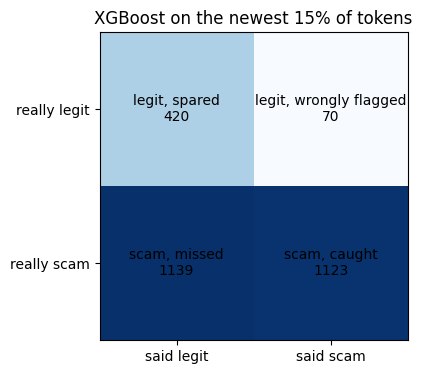

In [11]:
t = pick_threshold(model)
p_test = model.predict_proba(X.iloc[te])[:, 1]
cm = confusion_matrix(y.iloc[te], (p_test >= t).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
labels = [['legit, spared', 'legit, wrongly flagged'], ['scam, missed', 'scam, caught']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha='center', va='center', fontsize=10)
ax.set_xticks([0, 1], ['said legit', 'said scam']); ax.set_yticks([0, 1], ['really legit', 'really scam'])
ax.set_title('XGBoost on the newest 15% of tokens'); plt.show()

## Part 6b · Why did it give that score? (SHAP explanations)

**What this does:** Uses SHAP to split each token's score into contributions from each feature, then turns the top three into plain-English reasons.

**Why:** A buyer should learn *why* a token looks risky, and a score with no reasons would be a black box. SHAP is a standard method for explaining tree models like XGBoost.

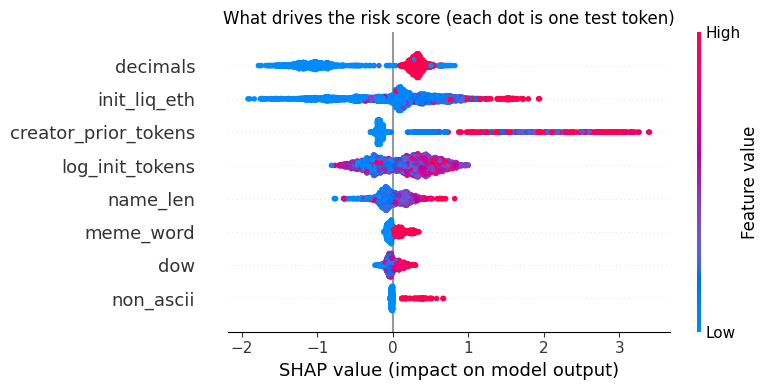

In [12]:
import shap
explainer = shap.TreeExplainer(model)
shap_test = explainer.shap_values(X.iloc[te])

plt.figure()
shap.summary_plot(shap_test, X.iloc[te], show=False, plot_size=(8, 4))
plt.title('What drives the risk score (each dot is one test token)'); plt.tight_layout(); plt.show()

**What this does:** Defines the sentences we show a buyer for each feature, and a function that returns a token's score (0 to 100), a traffic light and its top three reasons.

**Why:** This is the heart of the demo: the same function feeds the demo page.

In [13]:
DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
def sentence(feature, v):
    if feature == 'init_liq_eth':         return f"The creator put {v:,.1f} ETH into the trading pool at launch"
    if feature == 'log_init_tokens':      return f"About {10 ** v:,.0f} tokens were put into the pool"
    if feature == 'decimals':             return f"The token uses {v:.0f} decimal places (most tokens use 18)"
    if feature == 'creator_prior_tokens': return f"The same creator launched {v:.0f} token(s) before this one"
    if feature == 'meme_word':            return "The name uses hype words like 'inu', 'doge' or 'moon'" if v else "The name has no common hype words"
    if feature == 'non_ascii':            return "The name or symbol contains emoji or unusual characters" if v else "The name uses plain characters"
    if feature == 'name_len':             return f"The name is {v:.0f} characters long"
    if feature == 'dow':                  return f"It launched on a {DAYS[int(v)]}"
    return f"{feature} = {v}"   # any feature added later without a sentence yet

THRESHOLD = pick_threshold(model)
def explain_token(i):
    # i = row number in the full table; returns score, light and reasons
    x = X.loc[[i]]
    p = float(model.predict_proba(x)[0, 1])
    sv = explainer.shap_values(x)[0]
    order = np.argsort(-np.abs(sv))[:3]
    reasons = [(sentence(X.columns[k], x.iloc[0, k]), 'raises risk' if sv[k] > 0 else 'lowers risk') for k in order]
    light = '🔴 High risk' if p >= THRESHOLD else ('🟡 Caution' if p >= 0.50 else '🟢 Lower risk')   # red = the model's alert threshold; yellow = 50 up to it
    return round(100 * p), light, reasons

example = raw.index[te][0]
print(raw.loc[example, 'token00.name'], explain_token(example))

ShibTokyo | t.me/ShibTokyo (96, '🔴 High risk', [('The token uses 9 decimal places (most tokens use 18)', 'lowers risk'), ('The same creator launched 1 token(s) before this one', 'raises risk'), ('About 1,000,000,000,000 tokens were put into the pool', 'raises risk')])


## Part 6c · The demo page (Gradio)

**What this does:** Builds a small web page: pick a token from the test set (tokens the model never trained on) and see its risk score, traffic light, top three reasons, and what actually happened to it.

**Why:** A real input goes in and a result comes out. Showing what really happened makes every demo an honest test.

In [14]:
import gradio as gr
rng = np.random.default_rng(7)
test_rows = raw.index[te]
demo_rows = list(rng.choice(test_rows[raw.loc[test_rows, 'is_rug'] == 0], 12, replace=False)) + \
            list(rng.choice(test_rows[raw.loc[test_rows, 'is_rug'] == 1], 18, replace=False))
choices = {f"{raw.loc[i, 'token00.name']} ({raw.loc[i, 'token00.symbol']}), launched {raw.loc[i, 'created'].date()}": i
           for i in sorted(demo_rows, key=lambda i: str(raw.loc[i, 'token00.name']).lower())}

def what_happened(i):
    if raw.loc[i, 'is_rug'] == 1:
        return f"Rug pull, {raw.loc[i, 'rugpull_proceeding_hour'].rstrip('h')[:5]} hours after launch."
    return "No rug pull recorded."

def score_page(label):
    i = choices[label]
    score, light, reasons = explain_token(i)
    lines = '\n'.join(f"- {text} → **{effect}**" for text, effect in reasons)
    return (f"## {light}: {score}/100\n\n**Top reasons**\n{lines}\n\n"
            f"**What actually happened:** {what_happened(i)}\n\n"
            f"---\n*This project is a prototype and is not financial advice.*")

with gr.Blocks(title='Rug-Pull Radar') as demo:
    gr.Markdown("# 🛡️ Rug-Pull Radar\nPick a token the model has never seen. You get its scam-risk score and the reasons, using only what was visible at launch.")
    pick = gr.Dropdown(list(choices), label='Token (from the test set)')
    out = gr.Markdown()
    pick.change(score_page, pick, out)

print(score_page(list(choices)[0]))
if IN_COLAB:
    demo.launch(share=True)

## 🔴 High risk: 100/100

**Top reasons**
- The same creator launched 17 token(s) before this one → **raises risk**
- About 1,000,000,000 tokens were put into the pool → **raises risk**
- The token uses 18 decimal places (most tokens use 18) → **raises risk**

**What actually happened:** Rug pull, 0.696 hours after launch.

---
*This project is a prototype and is not financial advice.*
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://607c9944a5df8112fa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Part 6d · Where it fails, and who it's unfair to

**What this does:** Finds the test tokens the model got most confidently wrong: scams it rated safest, and legit tokens it rated riskiest, with the reasons it gave.

**Why:** The brief requires at least one failure example with an explanation. Looking at mistakes is also how we decide what to improve.

In [15]:
test_df = raw.iloc[te].assign(score=p_test, flagged=(p_test >= t).astype(int))
missed = test_df[(test_df.is_rug == 1) & (test_df.flagged == 0)].nsmallest(2, 'score')
false_alarms = test_df[(test_df.is_rug == 0) & (test_df.flagged == 1)].nlargest(2, 'score')
for title, rows in [('MISSED SCAMS (rated safest)', missed), ('FALSE ALARMS (legit, rated riskiest)', false_alarms)]:
    print(title)
    for i, row in rows.iterrows():
        score, light, reasons = explain_token(i)
        print(f"  {row['token00.name']} ({row['token00.symbol']}), score {score}/100. {what_happened(i)}")
        for text, effect in reasons:
            print(f"     - {text} -> {effect}")
    print()

MISSED SCAMS (rated safest)
  NFT Rise (https://t.me/nftrise) (NFT Rise), score 33/100. Rug pull, 526.3 hours after launch.
     - The creator put 0.5 ETH into the trading pool at launch -> lowers risk
     - The token uses 9 decimal places (most tokens use 18) -> lowers risk
     - About 925,000,000,000,000 tokens were put into the pool -> lowers risk
  FlokiX (FLOKIX), score 37/100. Rug pull, 761.3 hours after launch.
     - The creator put 1.0 ETH into the trading pool at launch -> lowers risk
     - The token uses 9 decimal places (most tokens use 18) -> lowers risk
     - About 36,000,000,000,000,036 tokens were put into the pool -> lowers risk

FALSE ALARMS (legit, rated riskiest)
  Frunkpuppy (FRUNKPUPPY), score 99/100. No rug pull recorded.
     - The same creator launched 23 token(s) before this one -> raises risk
     - About 1,000,000,000 tokens were put into the pool -> raises risk
     - The creator put 35.0 ETH into the trading pool at launch -> raises risk
  Kawakami Inu

**What this does:** Compares false alarms (legit tokens wrongly flagged) for small projects versus bigger ones, split by how much ETH the creator put in the pool at launch.

**Why:** The Finance track rewards fairness, and the Hacker Guide asks us to check whether the model works equally well across groups. A tool that mostly wrongly accuses small honest projects would be unfair to them.

In [16]:
legit = test_df[test_df.is_rug == 0].copy()
legit['pool size at launch'] = pd.cut(legit['initial_Liquidity_Eth'], [-1, 2, 10, np.inf],
                                      labels=['small (2 ETH or less)', 'medium (2 to 10 ETH)', 'large (over 10 ETH)'])
fair = legit.groupby('pool size at launch', observed=True)['flagged'].agg(['count', 'mean'])
fair.columns = ['legit tokens in test', 'share wrongly flagged']
fair.round(2)

,legit tokens in test,share wrongly flagged
pool size at launch,,
small (2 ETH or less),213,0.05
medium (2 to 10 ETH),208,0.18
large (over 10 ETH),69,0.30


### What we've learned so far
Through this project, I've learned that identifying rug pulls is more complicated than simply looking for suspicious activity. One of my biggest takeaways was the importance of preventing data leakage. Initially, the model achieved an almost perfect score, but I realized that some of the features were using information collected after a rug pull had already happened. This taught us that a model's accuracy is only meaningful if it uses information that would actually be available when someone needs it.

I also learned the importance of comparing AI models against simpler baseline approaches. Rather than assuming the XGBoost model is effective, I evaluated it against two baselines: one that labels every token as a scam and another that uses a single feature-based rule. I focused on both PR-AUC and balanced accuracy to determine whether our model actually improves upon these simpler methods.

Another important takeaway was the trade-off between catching scams and incorrectly flagging legitimate projects. The analysis specifically examined how many legitimate tokens the model incorrectly identified as scams compared with the baseline that flags every token. This helped me understand why false positives matter, particularly for smaller projects that could be unfairly labeled as fraudulent.

Ultimately, I learned that building a useful AI-powered safety tool isn't just about catching as many scams as possible. It's about creating a model that is accurate, reliable, transparent, and fair to legitimate projects.

## Part 7 · Rebuild first-hour features with Etherscan


**What this does:** Connects to Etherscan, a free public website that lets programs read the Ethereum blockchain, and tests the connection on one token.

**Why:** The dataset's own trading numbers leak (Part 3), so we re-measure every token over exactly the same window: its first hour.

In [17]:
import time, json, requests
if IN_COLAB:
    from google.colab import userdata
    ETHERSCAN_KEY = userdata.get('ETHERSCAN_KEY')
else:
    ETHERSCAN_KEY = os.environ.get('ETHERSCAN_KEY', '')
API = 'https://api.etherscan.io/v2/api'
BLOCKS_PER_HOUR = 275   # Ethereum made a block about every 13 seconds in 2020-21

FETCH_HOURS = 6        # we download 6 hours once, then measure both a 1-hour and a 6-hour window from it

def _one_page(pair, from_block, to_block, page):
    params = dict(chainid=1, module='logs', action='getLogs', address=pair, fromBlock=from_block,
                  toBlock=to_block, page=page, offset=1000, apikey=ETHERSCAN_KEY)
    for attempt in range(4):
        r = requests.get(API, params=params, timeout=30).json()
        if r.get('status') == '1':
            return r['result']
        if 'No records' in str(r.get('message', '')) or r.get('result') == []:
            return []
        time.sleep(1 + attempt)          # rate limit or temporary error: wait and retry
    raise RuntimeError(f"Etherscan error for {pair}: {r}")

def pool_logs(pair, from_block, to_block):
    # all events emitted by the trading pool (adds, removes, trades, LP-token moves) in a block range;
    # Etherscan returns at most 1,000 per page, so busy pools take several pages (10 pages max)
    logs = []
    for page in range(1, 11):
        batch = _one_page(pair, from_block, to_block, page)
        logs += batch
        if len(batch) < 1000:
            break
        time.sleep(0.22)
    return logs

HAVE_KEY = bool(ETHERSCAN_KEY)
if HAVE_KEY:
    test = raw.iloc[0]
    logs = pool_logs(test['id'], int(test['createdAtBlockNumber']), int(test['createdAtBlockNumber']) + FETCH_HOURS * BLOCKS_PER_HOUR)
    print(f"Test token {test['token00.name']}: {len(logs)} pool events in its first {FETCH_HOURS} hours")
else:
    print('No ETHERSCAN_KEY found in Colab Secrets, so Part 7 is skipped. Add the key and rerun from here.')

Test token StakeCoin: 115 pool events in its first 6 hours


**What this does:** Turns each pool's raw events into early-trading features (for the first hour, and separately for the first 6 hours): number of trades, buys vs sells, number of different buyers, liquidity added or removed, how much ETH is in the pool at the one-hour mark, and whether the creator burned (locked away) their pool tokens.

**Why:** These describe how the token behaves right after launch, which is the moment our buyer is deciding.

In [18]:
TOPIC = {'mint': '0x4c209b5fc8ad50758f13e2e1088ba56a560dff690a1c6fef26394f4c03821c4f',
         'burn': '0xdccd412f0b1252819cb1fd330b93224ca42612892bb3f4f789976e6d81936496',
         'swap': '0xd78ad95fa46c994b6551d0da85fc275fe613ce37657fb8d5e3d130840159d822',
         'sync': '0x1c411e9a96e071241c2f21f7726b17ae89e3cab4c78be50e062b03a9fffbad1',
         'transfer': '0xddf252ad1be2c89b69c2b068fc378daa952ba7f163c4a11628f55a4df523b3ef'}
DEAD = {'0x' + '0' * 40, '0x000000000000000000000000000000000000dead'}
WETH = '0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2'

def words(data):            # split an event's data field into 32-byte numbers
    h = data[2:]
    return [int(h[i:i + 64], 16) for i in range(0, len(h), 64)]

def addr(topic):            # last 20 bytes of a 32-byte topic = an address
    return '0x' + topic[-40:]

def hour_one_features(row, logs, max_block=None):
    # max_block: only count events up to this block (e.g. the end of hour one)
    if max_block is not None:
        logs = [lg for lg in logs if int(lg['blockNumber'], 16) <= max_block]
    weth_is_0 = str(row.get('token0.name', '')) == 'Wrapped Ether'
    f = dict(n_swaps=0, n_buys=0, n_sells=0, n_mints=0, n_burns=0, eth_bought=0.0, eth_sold=0.0,
             lp_burned=0.0, lp_minted=0.0, eth_in_pool_1h=np.nan)
    buyers = set()
    for lg in logs:
        t0 = lg['topics'][0].lower()
        if t0 == TOPIC['swap']:
            a0in, a1in, a0out, a1out = words(lg['data'])[:4]
            eth_in = (a0in if weth_is_0 else a1in) / 1e18
            eth_out = (a0out if weth_is_0 else a1out) / 1e18
            f['n_swaps'] += 1
            if eth_in > 0:
                f['n_buys'] += 1; f['eth_bought'] += eth_in; buyers.add(addr(lg['topics'][2]))
            else:
                f['n_sells'] += 1; f['eth_sold'] += eth_out
        elif t0 == TOPIC['mint']:
            f['n_mints'] += 1
        elif t0 == TOPIC['burn']:
            f['n_burns'] += 1
        elif t0 == TOPIC['sync']:
            r0, r1 = words(lg['data'])[:2]
            f['eth_in_pool_1h'] = (r0 if weth_is_0 else r1) / 1e18   # last Sync = pool balance at the end of hour one
        elif t0 == TOPIC['transfer'] and len(lg['topics']) >= 3:
            src, dst = addr(lg['topics'][1]), addr(lg['topics'][2])
            amount = words(lg['data'])[0] if lg['data'] != '0x' else 0
            if src == '0x' + '0' * 40:
                f['lp_minted'] += amount
            elif dst in DEAD:
                f['lp_burned'] += amount
    f['unique_buyers'] = len(buyers)
    f['lp_burned_share'] = f['lp_burned'] / f['lp_minted'] if f['lp_minted'] else 0.0
    f['sell_buy_ratio'] = f['n_sells'] / max(f['n_buys'], 1)
    f['pool_change_1h'] = (f['eth_in_pool_1h'] / row['initial_Liquidity_Eth'] - 1) if row['initial_Liquidity_Eth'] else np.nan
    f['hit_1000_cap'] = int(len(logs) >= 1000)   # very busy pool: over 1,000 events in the window
    del f['lp_burned'], f['lp_minted']
    return f
if HAVE_KEY:
    print(hour_one_features(test, logs, int(test['createdAtBlockNumber']) + BLOCKS_PER_HOUR))

{'n_swaps': 48, 'n_buys': 29, 'n_sells': 19, 'n_mints': 2, 'n_burns': 0, 'eth_bought': 21.106014891211746, 'eth_sold': 22.69289194009207, 'eth_in_pool_1h': nan, 'unique_buyers': 22, 'lp_burned_share': 0.0, 'sell_buy_ratio': 0.6551724137931034, 'pool_change_1h': np.float64(nan), 'hit_1000_cap': 0}


**What this does:** Picks the tokens to re-measure: every legitimate token plus 3,000 randomly chosen rug pulls, skipping rug pulls that happened inside the first hour (at the one-hour mark, their pool is already empty, so there's nothing left to predict). Then it downloads each pool's first 6 hours of events once and measures both windows from it, saving progress so it can resume if Colab disconnects.

**Why:** About 4,800 tokens at roughly 4 requests a second takes about 30 to 40 minutes (busy pools need extra pages), within the free Etherscan limits of 5 per second and 100,000 per day.

In [19]:
hours_to_rug = raw['rugpull_proceeding_hour'].str.rstrip('h').astype(float)
eligible = raw[(raw['is_rug'] == 0) | (hours_to_rug >= 1)]
sample = pd.concat([eligible[eligible.is_rug == 0],
                    eligible[eligible.is_rug == 1].sample(3000, random_state=42)]).sort_values('created')
print(f"{len(sample)} tokens to re-measure ({(sample.is_rug == 0).sum()} legit, {(sample.is_rug == 1).sum()} rug pulls)")
print(f"Rug pulls skipped because they happened within the first hour: {((raw.is_rug == 1) & (hours_to_rug < 1)).sum()}")

cache_path = os.path.join(DATA_DIR, 'early_features_1h_6h.jsonl')
done = set()
if os.path.exists(cache_path):
    done = {json.loads(l)['id'] for l in open(cache_path)}
print('Already fetched:', len(done))

if not HAVE_KEY:
    print('Skipped: no Etherscan key yet.')
else:
    start, new = time.time(), 0
    with open(cache_path, 'a') as out:
        for i, (_, row) in enumerate(sample.iterrows()):
            if row['id'] in done:
                continue
            b = int(row['createdAtBlockNumber'])
            try:
                lg = pool_logs(row['id'], b, b + FETCH_HOURS * BLOCKS_PER_HOUR)
                f1 = hour_one_features(row, lg, b + BLOCKS_PER_HOUR)
                f6 = hour_one_features(row, lg, b + 6 * BLOCKS_PER_HOUR)
                feats = {**f1, **{'h6_' + k: v for k, v in f6.items()}}
            except Exception as e:
                print('skip', row['id'], e); continue
            out.write(json.dumps({'id': row['id'], **feats}) + '\n')
            time.sleep(0.22)
            new += 1
            if new % 25 == 0:          # progress meter: prints every 25 tokens, with a time estimate
                out.flush()
                left = (len(sample) - len(done) - new) * (time.time() - start) / new / 60
                print(f"{len(done) + new}/{len(sample)} tokens done | about {left:.0f} min left", flush=True)
    print('Finished.')

4837 tokens to re-measure (1837 legit, 3000 rug pulls)
Rug pulls skipped because they happened within the first hour: 4341
Already fetched: 4837
Finished.


## Part 7b · Retrain with first-hour features and measure the improvement *(run Saturday, after Part 7)*

**What this does:** Joins the first-hour features to the launch features, then trains the same XGBoost twice on the same tokens: once with launch features only (before) and once with launch plus first-hour features (after).

**Why:** This is our one measured improvement. Using the same tokens and the same split for both makes the comparison fair.

In [20]:
H1_COLS = ['n_swaps', 'n_buys', 'n_sells', 'n_mints', 'n_burns', 'eth_bought', 'eth_sold', 'eth_in_pool_1h',
           'unique_buyers', 'lp_burned_share', 'sell_buy_ratio', 'pool_change_1h', 'hit_1000_cap']
if os.path.exists(cache_path):
    h1 = pd.read_json(cache_path, lines=True).drop_duplicates('id').set_index('id')
    s_rows = raw.reset_index().merge(h1, left_on='id', right_index=True)   # keeps the original row number in 'index'
    s_rows = s_rows.sort_values(['created', 'index']).set_index('index')
    print(f"{len(s_rows)} tokens with first-hour data ({(s_rows.is_rug == 0).sum()} legit, {(s_rows.is_rug == 1).sum()} rug pulls)")
    X2 = pd.concat([X.loc[s_rows.index], s_rows[H1_COLS]], axis=1)
    y2 = s_rows['is_rug']
    m2 = len(X2); a2, b2 = int(m2 * 0.70), int(m2 * 0.85)
    tr2, va2, te2 = slice(0, a2), slice(a2, b2), slice(b2, m2)
    print('test tokens launched', s_rows['created'].iloc[b2].date(), 'to', s_rows['created'].iloc[-1].date(), f'| rug share {y2.iloc[te2].mean():.1%}')
else:
    print('No first-hour data yet: run Part 7 first.')

4837 tokens with first-hour data (1837 legit, 3000 rug pulls)
test tokens launched 2021-09-06 to 2021-11-14 | rug share 43.9%


**What this does:** Scores the baselines on this sample, including a new rule a careful buyer could check by hand: 'flag it if the creator did not burn any pool tokens in the first hour' (so they can still drain the pool). Then trains before and after models.

**Why:** The new rule is the fair simple baseline for first-hour data, the way 'pool > 4 ETH' was for launch data.

In [21]:
def fit_eval(cols, label):
    m = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, eval_metric='aucpr', random_state=42)
    m.fit(X2[cols].iloc[tr2], y2.iloc[tr2])
    pv = m.predict_proba(X2[cols].iloc[va2])[:, 1]
    grid = np.linspace(0.05, 0.99, 95)
    thr = grid[np.argmax([balanced_accuracy_score(y2.iloc[va2], (pv >= g).astype(int)) for g in grid])]
    p = m.predict_proba(X2[cols].iloc[te2])[:, 1]
    return m, thr, report(label, y2.iloc[te2], (p >= thr).astype(int), p)

if os.path.exists(cache_path):
    res2 = [report('Baseline 1: everything is a scam', y2.iloc[te2], np.ones(m2 - b2, int)),
            report('Baseline 3: flag if no LP tokens burned in hour one', y2.iloc[te2],
                   (X2['lp_burned_share'].iloc[te2] <= 0).astype(int))]
    model_before, thr_before, r = fit_eval(list(X.columns), 'Before: launch features only'); res2.append(r)
    model_after, thr_after, r = fit_eval(list(X2.columns), 'After: launch + first-hour features'); res2.append(r)
    improvement_table = pd.DataFrame(res2).set_index('method').round(3)
    display(improvement_table) if IN_COLAB else print(improvement_table.to_string())

,scams caught (recall),flags that were scams (precision),legit tokens wrongly flagged,balanced accuracy,PR-AUC
method,,,,,
Baseline 1: everything is a scam,1.000,0.439,1.000,0.500,NaN
Baseline 3: flag if no LP tokens burned in hour one,0.981,0.441,0.973,0.504,NaN
Before: launch features only,0.433,0.821,0.074,0.679,0.739
After: launch + first-hour features,0.596,0.880,0.064,0.766,0.853


**What this does:** Compares an hour-one model with a six-hour model. Both are scored on the same test tokens that were still alive at hour six, and then on the question that matters most: out of ALL rug pulls in the test period, what share does each model warn about before the rug happens?

**Why:** Waiting longer gives the model more trading to learn from, so it may be more accurate. But every hour of waiting lets more scams finish first. This table shows that trade-off in numbers.

In [22]:
if os.path.exists(cache_path):
    H6_COLS = ['h6_' + c for c in H1_COLS]
    hrs = raw['rugpull_proceeding_hour'].str.rstrip('h').astype(float)
    alive6 = ((s_rows['is_rug'] == 0) | (hrs.loc[s_rows.index] >= 6)).values
    pos = np.arange(m2)
    tr6, va6, te6 = alive6 & (pos < a2), alive6 & (pos >= a2) & (pos < b2), alive6 & (pos >= b2)
    X6 = pd.concat([X.loc[s_rows.index], s_rows[H6_COLS]], axis=1)

    m6 = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.8, eval_metric='aucpr', random_state=42)
    m6.fit(X6[tr6], y2[tr6])
    pv6 = m6.predict_proba(X6[va6])[:, 1]
    grid = np.linspace(0.05, 0.99, 95)
    thr6 = grid[np.argmax([balanced_accuracy_score(y2[va6], (pv6 >= g).astype(int)) for g in grid])]

    # share of ALL rug pulls in the test period (including fast ones we left out of the sample) that are still running at each hour
    period = (raw['created'] >= s_rows['created'].iloc[b2]) & (raw['is_rug'] == 1)
    still_running = {1: (hrs[period] >= 1).mean(), 6: (hrs[period] >= 6).mean()}

    rows = []
    for label, mdl, Xw, thr, hours in [('Hour-one model', model_after, X2, thr_after, 1), ('Six-hour model', m6, X6, thr6, 6)]:
        p = mdl.predict_proba(Xw[te6])[:, 1]
        r = report(label, y2[te6], (p >= thr).astype(int), p)
        if hours == 1:   # recall of the hour-one model on ALL its test rug pulls (alive at hour one)
            p_all = mdl.predict_proba(Xw.iloc[te2])[:, 1]
            rec = ((p_all >= thr) & (y2.iloc[te2] == 1)).sum() / (y2.iloc[te2] == 1).sum()
        else:
            rec = r['scams caught (recall)']
        r['rug pulls still running at that hour'] = still_running[hours]
        r['share of ALL rug pulls warned in time'] = rec * still_running[hours]
        rows.append(r)
    window_table = pd.DataFrame(rows).set_index('method').round(3)
    print('Scored on test tokens still alive at hour six; last column covers every rug pull in the test period.')
    display(window_table) if IN_COLAB else print(window_table.to_string())

Scored on test tokens still alive at hour six; last column covers every rug pull in the test period.


,scams caught (recall),flags that were scams (precision),legit tokens wrongly flagged,balanced accuracy,PR-AUC,rug pulls still running at that hour,share of ALL rug pulls warned in time
method,,,,,,,
Hour-one model,0.590,0.859,0.064,0.763,0.825,0.730,0.435
Six-hour model,0.593,0.874,0.057,0.768,0.841,0.617,0.366


**What this does:** Adds plain-English sentences for the new first-hour features and points the explanations and demo page at the new model.

**Why:** So the demo's reasons now include things like 'the creator kept all their pool tokens' or '40 different wallets bought in the first hour'.

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


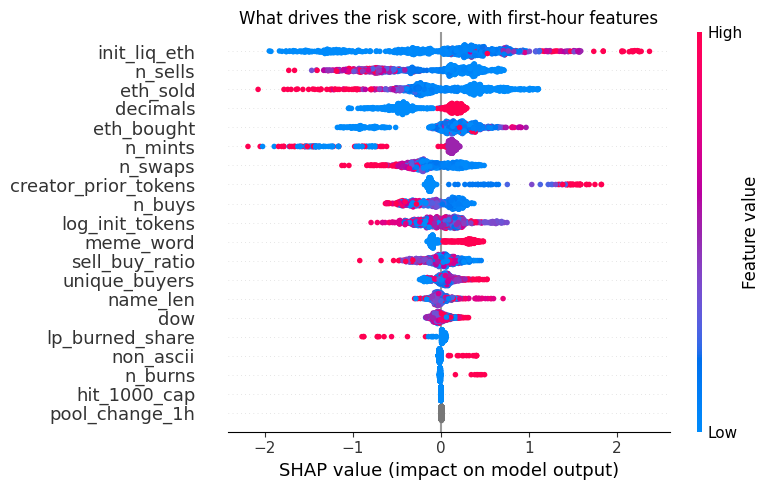

Demo now uses the first-hour model; 14 tokens in the dropdown. Rerun Part 6c or Part 8 to relaunch the page.


In [23]:
if os.path.exists(cache_path):
    _base_sentence = sentence
    def sentence(feature, v):
        if feature == 'lp_burned_share':  return f"The creator burned {v:.0%} of their pool tokens in hour one" if v > 0 else "The creator kept all their pool tokens (they can still pull the money out)"
        if feature == 'unique_buyers':    return f"{v:.0f} different wallets bought in the first hour"
        if feature == 'n_swaps':          return f"{v:.0f} trades happened in the first hour"
        if feature == 'n_buys':           return f"{v:.0f} buys in the first hour"
        if feature == 'n_sells':          return f"{v:.0f} sells in the first hour"
        if feature == 'sell_buy_ratio':   return f"There were {v:.2f} sells for every buy"
        if feature == 'eth_bought':       return f"Buyers put in {v:,.2f} ETH in the first hour"
        if feature == 'eth_sold':         return f"Sellers took out {v:,.2f} ETH in the first hour"
        if feature == 'eth_in_pool_1h':   return f"The pool held {v:,.2f} ETH at the one-hour mark"
        if feature == 'pool_change_1h':   return f"The pool's ETH changed by {v:+.0%} in the first hour"
        if feature == 'n_mints':          return f"Liquidity was added {v:.0f} time(s) in the first hour"
        if feature == 'n_burns':          return f"Liquidity was removed {v:.0f} time(s) in the first hour"
        if feature == 'hit_1000_cap':     return "Very busy: over 1,000 pool events in the first hour" if v else "Under 1,000 pool events in the first hour"
        return _base_sentence(feature, v)

    model, X, THRESHOLD = model_after, X2, thr_after          # the demo and explanations now use the new model
    explainer = shap.TreeExplainer(model)
    plt.figure(); shap.summary_plot(explainer.shap_values(X.iloc[te2]), X.iloc[te2], show=False, plot_size=(8, 5))
    plt.title('What drives the risk score, with first-hour features'); plt.tight_layout(); plt.show()
    choices = {k: v for k, v in choices.items() if v in X.index} or \
              {f"{raw.loc[i, 'token00.name']} ({raw.loc[i, 'token00.symbol']}), launched {raw.loc[i, 'created'].date()}": i
               for i in X.index[te2][:30]}
    print('Demo now uses the first-hour model;', len(choices), 'tokens in the dropdown. Rerun Part 6c or Part 8 to relaunch the page.')

## Part 8 · Add-on: the Pump-and-Dump Alarm *(Sunday, only if the core is done by 11:30 AM)*

**What this does:** Downloads about 2,800 Telegram messages that researchers hand-labeled as pump-and-dump announcements or not, and builds a clean table: text and date only, with usernames, links and phone numbers masked.

**Why:** Scammers hype a coin before dumping it. A second signal that reads the hype message pairs well with the rug-pull score.

In [24]:
# Pump-and-Dump Alarm: a simple text classifier for crypto Telegram messages
# ---------------------------------------------------------------------------
# Data: human-labeled Telegram messages from the SIGMOD 2023 paper
#   "Sequence-based Target Coin Prediction for Cryptocurrency Pump-and-Dump"
#   (Hu et al.), repo github.com/Bayi-Hu/Pump-and-Dump-Detection-on-Cryptocurrency
#   Labels in Data/Telegram/Labeled/label.txt:
#     1 = pump-and-dump announcement   -> our POSITIVE class
#     2 = ordinary trading signal ("buy X, targets..., stop loss")  -> negative
#     0 = anything else (chat, news, ads)                           -> negative
#     ? = unsure                                                    -> dropped
#   Message text lives in Data/Telegram/raw/<channel_id>.pkl (pickled lists of dicts).
#
# Runs in free Google Colab (pandas + scikit-learn only, ~75 MB download).
# Privacy: we keep ONLY the message text + date, and strip usernames,
# links and phone numbers. No user ids are kept.

import os, io, re, pickle, datetime, urllib.request, urllib.error
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# Pinned to a fixed commit so results are reproducible.
COMMIT = "17e398f99558c52a472728d4a5856f15313be079"
BASE = f"https://raw.githubusercontent.com/Bayi-Hu/Pump-and-Dump-Detection-on-Cryptocurrency/{COMMIT}/Data/Telegram/"
CACHE = "pd_data"
os.makedirs(CACHE, exist_ok=True)


def download(rel_path):
    """Download a file once and cache it. Returns local path, or None if missing (404)."""
    local = os.path.join(CACHE, rel_path.replace("/", "_"))
    if not os.path.exists(local):
        try:
            urllib.request.urlretrieve(BASE + rel_path, local)
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            raise
    return local


# Pickle files can run code when loaded. This "safe" loader only allows the
# three harmless datetime classes these files actually use, and blocks anything else.
class SafeUnpickler(pickle.Unpickler):
    ALLOWED = {("datetime", "datetime"), ("datetime", "timezone"), ("datetime", "timedelta")}

    def find_class(self, module, name):
        if (module, name) in self.ALLOWED:
            return getattr(datetime, name)
        raise pickle.UnpicklingError(f"blocked: {module}.{name}")


# ---- 1. Build the labeled table -------------------------------------------
labels = pd.read_csv(download("Labeled/label.txt"), sep=" ", header=None,
                     names=["label", "channel_id", "msg_id"], dtype=str)

rows = []
for cid in labels["channel_id"].unique():
    path = download(f"raw/{cid}.pkl")
    if path is None:          # 6 of 42 channels are not in the repo
        continue
    with open(path, "rb") as f:
        for m in SafeUnpickler(f).load():
            if isinstance(m, dict) and m.get("message"):
                rows.append((cid, str(m["id"]), m["message"], m["date"]))
texts = pd.DataFrame(rows, columns=["channel_id", "msg_id", "text", "date"])

df = labels.merge(texts, on=["channel_id", "msg_id"])
df = df[df["label"] != "?"].copy()
df["y"] = (df["label"] == "1").astype(int)        # 1 = pump announcement


def clean(t):
    t = re.sub(r"https?://\S+|www\.\S+|t\.me/\S+", " URL ", t)   # links
    t = re.sub(r"@\w+", " USER ", t)                              # usernames
    t = re.sub(r"\+\d[\d\s\-()]{7,}\d", " PHONE ", t)             # +international phone numbers
    return re.sub(r"\s+", " ", t).strip()


df["text"] = df["text"].map(clean)
df["date"] = pd.to_datetime(df["date"], utc=True)
# Pump channels repeat the same countdown posts. Keep the first copy only, so the
# same message can't appear in both train and test.
df["dedup_key"] = df["text"].str.lower().str.replace(r"[^a-z]", "", regex=True)
df = df.sort_values("date").drop_duplicates("dedup_key").reset_index(drop=True)
df = df[["date", "channel_id", "text", "label", "y"]]

print(f"Labeled messages: {len(df)}  |  pump={df.y.sum()}  not-pump={(df.y == 0).sum()}")
print(f"Dates: {df.date.min().date()} to {df.date.max().date()}  |  channels: {df.channel_id.nunique()}")

Labeled messages: 2783  |  pump=328  not-pump=2455
Dates: 2018-08-29 to 2021-11-18  |  channels: 34


**What this does:** Splits by date (train on older messages, test on newer), then compares a keyword rule ('pump', '100x', 'moon', 'buy now', rocket emoji, 'signal') with a TF-IDF + logistic regression text model.

**Why:** Same honesty rules as the main model: a simple baseline, a split by time, precision and recall.

In [25]:
# ---- 2. Train/test split BY DATE (train on the past, test on the future) ---
cut = df["date"].quantile(0.8)
train, test = df[df.date < cut], df[df.date >= cut]
print(f"Train: {len(train)} msgs before {cut.date()} (pump={train.y.sum()})  |  "
      f"Test: {len(test)} msgs after (pump={test.y.sum()})\n")


def pd_report(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print(f"{name:<28} precision={p:.2f}  recall={r:.2f}  F1={f:.2f}   (TP={tp} FP={fp} FN={fn} TN={tn})")


# ---- 3a. Keyword baseline --------------------------------------------------
KEYWORDS = ["pump", "100x", "moon", "buy now", "🚀", "signal"]


def keyword_flag(text):
    t = text.lower()
    return int(any(k in t for k in KEYWORDS))


pd_report("(a) Keyword baseline", test.y, test.text.map(keyword_flag))

# ---- 3b. TF-IDF + logistic regression --------------------------------------
vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr, Xte = vec.fit_transform(train.text), vec.transform(test.text)
clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0)
clf.fit(Xtr, train.y)
pred = clf.predict(Xte)
pd_report("(b) TF-IDF + LogReg", test.y, pred)

# Which words push a message toward "pump"? (explainability)
vocab = vec.get_feature_names_out()
order = clf.coef_[0].argsort()
print("\nTop 'pump' words:    ", ", ".join(vocab[order[-15:]][::-1]))
print("Top 'not pump' words:", ", ".join(vocab[order[:15]]))

# ---- 4. Mistakes on the test set -------------------------------------------
test = test.assign(pred=pred, prob=clf.predict_proba(Xte)[:, 1])
wrong = test[test.pred != test.y].sort_values("prob", key=lambda s: (s - 0.5).abs(), ascending=False)
print("\n5 test messages the model gets wrong (most confident first):")
for row in wrong.head(5).itertuples():
    kind = "FALSE ALARM (really not pump)" if row.y == 0 else "MISSED PUMP"
    print(f"- [{kind}, p(pump)={row.prob:.2f}, orig label {row.label}] {row.text[:160]!r}")

Train: 2226 msgs before 2021-03-19 (pump=281)  |  Test: 557 msgs after (pump=47)

(a) Keyword baseline         precision=0.17  recall=0.91  F1=0.28   (TP=43 FP=213 FN=4 TN=297)
(b) TF-IDF + LogReg          precision=0.81  recall=0.81  F1=0.81   (TP=38 FP=9 FN=9 TN=501)

Top 'pump' words:     coin, pump, left, minutes, sky, gmt, mth, mith, don sell, buy buy, and hold, mith now, time, ong, adx
Top 'not pump' words: profit, bitcoin, stop, target, call, bittrex, loss, stop loss, coming soon, some, new, user, below, premium, reached

5 test messages the model gets wrong (most confident first):
- [FALSE ALARM (really not pump), p(pump)=0.99, orig label 0] 'Attention Guys!! 24 hours left Biggest " Special PUMP signal " is coming Tomorrow We are going to see the Biggest Special ever with more than +300k participants'
- [FALSE ALARM (really not pump), p(pump)=0.98, orig label 0] 'Attention Guys!! Biggest " Special PUMP signal " is coming at 11th April We are going to see the Biggest Special eve

**What this does:** Tests on 9 Telegram channels the model never saw during training.

**Why:** If the score drops a lot, part of the model's skill was memorizing each group's writing style. This is the honest number to quote.

In [26]:
# ---- 5. Harder check: test on channels the model never saw -----------------
# Checks whether the model just memorises each channel's writing style
chans = sorted(df.channel_id.unique())
held = set(chans[::4])                      # every 4th channel held out
tr_ch, te_ch = df[~df.channel_id.isin(held)], df[df.channel_id.isin(held)]
v2 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
c2 = LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0).fit(v2.fit_transform(tr_ch.text), tr_ch.y)
print(f"\nUnseen-channel test ({len(held)} channels, {len(te_ch)} msgs, pump={te_ch.y.sum()}):")
pd_report("(a) Keyword baseline", te_ch.y, te_ch.text.map(keyword_flag))
pd_report("(b) TF-IDF + LogReg", te_ch.y, c2.predict(v2.transform(te_ch.text)))


# ---- 6. Try it yourself ----------------------------------------------------
def pump_alarm(message):
    p = clf.predict_proba(vec.transform([clean(message)]))[0, 1]
    return f"{'ALARM' if p >= 0.5 else 'ok   '}  p(pump)={p:.2f}  {message[:70]!r}"


print()
for msg in ["⏰ 10 minutes until the pump! Next post will be the coin name. Exchange: Binance",
            "BTC broke resistance at 60k, long with stop loss at 58k, targets 62k-64k",
            "Big news: Ethereum upgrade scheduled for next month, devs confirm timeline"]:
    print(pump_alarm(msg))


Unseen-channel test (9 channels, 993 msgs, pump=58):
(a) Keyword baseline         precision=0.12  recall=0.79  F1=0.20   (TP=46 FP=351 FN=12 TN=584)
(b) TF-IDF + LogReg          precision=0.49  recall=0.52  F1=0.50   (TP=30 FP=31 FN=28 TN=904)

ALARM  p(pump)=1.00  '⏰ 10 minutes until the pump! Next post will be the coin name. Exchange'
ok     p(pump)=0.02  'BTC broke resistance at 60k, long with stop loss at 58k, targets 62k-6'
ok     p(pump)=0.09  'Big news: Ethereum upgrade scheduled for next month, devs confirm time'


**What this does:** Rebuilds the demo page with two tabs: the Rug-Pull Radar from Part 6c, and a Pump Alarm tab where you paste a message and see its pump score and the words that drove it.

**Why:** Together they form the Crypto Safety Copilot: one checks the token, the other checks the hype message that tells you to buy it.

In [27]:
def pump_page(message):
    if not message or not message.strip():
        return "Paste a message to check it."
    x = vec.transform([clean(message)])
    p = float(clf.predict_proba(x)[0, 1])
    contrib = x.toarray()[0] * clf.coef_[0]
    top = [vocab[k] for k in contrib.argsort()[::-1][:3] if contrib[k] > 0]
    light = '🔴 Looks like a pump-and-dump call' if p >= 0.5 else '🟢 Doesn\'t look like a pump call'
    why = ', '.join(f"'{w}'" for w in top) if top else 'no strong pump words'
    return (f"## {light}: {round(100 * p)}/100\n\n**Words that raised the score:** {why}\n\n"
            f"---\n*Honest note: on chat groups it never saw, this model catches about half of pump calls (F1 0.50).*\n\n"
            f"*This project is a prototype and is not financial advice.*")

with gr.Blocks(title='Crypto Safety Copilot') as copilot:
    gr.Markdown("# 🛡️ Crypto Safety Copilot\nTwo checks before you put money in: the token, and the message telling you to buy it.")
    with gr.Tab('Rug-Pull Radar'):
        pick2 = gr.Dropdown(list(choices), label='Token (from the test set)')
        out2 = gr.Markdown()
        pick2.change(score_page, pick2, out2)
    with gr.Tab('Pump Alarm'):
        msg = gr.Textbox(label='Paste a crypto message', lines=4,
                         value='⏰ 10 minutes until the pump! Next post will be the coin name. Exchange: Binance')
        out3 = gr.Markdown()
        gr.Button('Check message').click(pump_page, msg, out3)

print(pump_page('⏰ 10 minutes until the pump! Next post will be the coin name. Exchange: Binance'))
print(pump_page('BTC broke resistance at 60k, long with stop loss at 58k'))
if IN_COLAB:
    demo.close()
    copilot.launch(share=True)

## 🔴 Looks like a pump-and-dump call: 100/100

**Words that raised the score:** 'coin', 'pump', 'minutes'

---
*Honest note: on chat groups it never saw, this model catches about half of pump calls (F1 0.50).*

*This project is a prototype and is not financial advice.*
## 🟢 Doesn't look like a pump call: 2/100

**Words that raised the score:** 'with', 'resistance', 'broke'

---
*Honest note: on chat groups it never saw, this model catches about half of pump calls (F1 0.50).*

*This project is a prototype and is not financial advice.*
Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3db3720a0baa2f80f2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Part 9 · Live mode: paste a token address *(Sunday)*

**What this does:** Takes the address of any token traded on Uniswap V2 (the exchange in our data), finds its trading pool, and rebuilds the same launch features and first-hour features from the public blockchain using Etherscan. Then it scores it with our model and gives the top three reasons.

**Why:** This turns the project from a study of 2021 tokens into a tool someone could use on a token launched today.

In [28]:
FACTORY = '0x5c69bee701ef814a2b6a3edd4b1652cb9cc5aa6f'   # Uniswap V2 factory: creates every trading pool
LIVE_BLOCKS_PER_HOUR = 300                               # since 2022 Ethereum makes a block every 12 seconds

def ether(params):
    params = dict(chainid=1, apikey=ETHERSCAN_KEY, **params)
    for attempt in range(4):
        r = requests.get(API, params=params, timeout=30).json()
        if 'result' in r and r.get('status', '1') == '1' and not str(r.get('result', '')).startswith('Max rate'):
            return r['result']
        time.sleep(1 + attempt)
    raise RuntimeError(f"Etherscan error: {r}")

def call(contract, selector, arg=''):       # read a value from a smart contract (no transaction, free)
    return ether(dict(module='proxy', action='eth_call', to=contract, data=selector + arg, tag='latest'))

def text_from(hexdata):                     # decode a text value returned by a contract (name, symbol)
    h = hexdata[2:]
    try:
        n = int(h[64:128], 16); return bytes.fromhex(h[128:128 + 2 * n]).decode('utf-8', 'replace')
    except Exception:
        return bytes.fromhex(h[:64]).rstrip(b'\0').decode('utf-8', 'replace')   # some old tokens return fixed-size text

def pad(a):
    return a.lower().replace('0x', '').rjust(64, '0')

def creation(contract):                     # who created a contract, and in which block
    c = ether(dict(module='contract', action='getcontractcreation', contractaddresses=contract))[0]
    tx = ether(dict(module='proxy', action='eth_getTransactionByHash', txhash=c['txHash']))
    return c['contractCreator'].lower(), int(tx['blockNumber'], 16)

def live_features(address):
    address = address.strip().lower()
    pair = addr(call(FACTORY, '0xe6a43905', pad(address) + pad(WETH)))   # getPair(token, WETH)
    if int(pair, 16) == 0:
        raise ValueError('No Uniswap V2 pool paired with ETH was found for this address.')
    token0 = addr(call(pair, '0x0dfe1681'))
    name = text_from(call(address, '0x06fdde03'))
    symbol = text_from(call(address, '0x95d89b41'))
    decimals = int(call(address, '0x313ce567'), 16)
    creator, _ = creation(address)
    _, b = creation(pair)
    stamp = int(ether(dict(module='proxy', action='eth_getBlockByNumber', tag=hex(b), boolean='false'))['timestamp'], 16)
    launched = pd.Timestamp(stamp, unit='s')
    # earlier contracts deployed by the same creator (our stand-in for 'tokens launched before')
    txs = ether(dict(module='account', action='txlist', address=creator, startblock=0, endblock=b - 1, page=1, offset=1000, sort='asc'))
    prior = sum(1 for t in txs if t.get('contractAddress'))

    logs = pool_logs(pair, b, b + LIVE_BLOCKS_PER_HOUR)
    first_mint = next((lg for lg in logs if lg['topics'][0].lower() == TOPIC['mint']), None)
    if first_mint is None:
        raise ValueError('The pool has no liquidity events in its first hour.')
    a0, a1 = words(first_mint['data'])[:2]
    weth_is_0 = token0 == WETH
    eth_amt, tok_amt = (a0, a1) if weth_is_0 else (a1, a0)
    row = {'token0.name': 'Wrapped Ether' if weth_is_0 else '', 'initial_Liquidity_Eth': eth_amt / 1e18}

    f = {'init_liq_eth': eth_amt / 1e18,
         'log_init_tokens': np.log10(max(tok_amt / 10 ** decimals, 1e-9)),
         'decimals': decimals,
         'creator_prior_tokens': prior,
         'meme_word': int(any(w in name.lower() for w in ['inu', 'doge', 'shib', 'elon', 'moon', 'safe', 'baby', 'floki', 'pepe', 'rocket'])),
         'non_ascii': int(any(ord(c) > 127 for c in name + symbol)),
         'name_len': len(name),
         'dow': launched.dayofweek}
    f.update(hour_one_features(row, logs, b + LIVE_BLOCKS_PER_HOUR))
    hours_live = (pd.Timestamp.now('UTC').tz_localize(None) - launched).total_seconds() / 3600
    return name, symbol, launched, hours_live, f

def live_page(address):
    if not HAVE_KEY:
        return "Live mode needs the Etherscan key in Colab Secrets (see Part 7)."
    try:
        name, symbol, launched, hours_live, f = live_features(address)
    except Exception as e:
        return f"Couldn't score this address: {e}"
    x = pd.DataFrame([f]).reindex(columns=X.columns)     # same columns, same order as the model was trained on
    p = float(model.predict_proba(x)[0, 1])
    sv = explainer.shap_values(x)[0]
    order = np.argsort(-np.abs(sv))[:3]
    lines = '\n'.join(f"- {sentence(X.columns[k], x.iloc[0, k])} → **{'raises risk' if sv[k] > 0 else 'lowers risk'}**" for k in order)
    light = '🔴 High risk' if p >= THRESHOLD else ('🟡 Caution' if p >= 0.50 else '🟢 Lower risk')   # red = the model's alert threshold; yellow = 50 up to it
    young = "\n\n⚠️ *Launched less than an hour ago, so the first hour isn't complete yet. Check again later.*" if hours_live < 1 else ''
    return (f"## {name} ({symbol}) · {light}: {round(100 * p)}/100\n\nPool opened {launched:%b %d %Y, %H:%M} UTC. Scored on its first hour.{young}\n\n"
            f"**Top reasons**\n{lines}\n\n---\n*Honest note: the model learned from 2020–21 tokens; scam tactics change, so live scores are less reliable than our test results.*\n\n"
            f"*This project is a prototype and is not financial advice.*")

if HAVE_KEY:
    # try it on a token from our data (scored on its first hour; the label says what really happened)
    tok = raw.loc[raw.index[te][0]]
    print(live_page(tok['token00.id']))

## ShibTokyo | t.me/ShibTokyo (ShibTokyo) · 🔴 High risk: 84/100

Pool opened Aug 15 2021, 15:40 UTC. Scored on its first hour.

**Top reasons**
- The token uses 9 decimal places (most tokens use 18) → **lowers risk**
- Liquidity was removed 1 time(s) in the first hour → **raises risk**
- The name is 26 characters long → **raises risk**

---
*Honest note: the model learned from 2020–21 tokens; scam tactics change, so live scores are less reliable than our test results.*

*This project is a prototype and is not financial advice.*


**What this does:** Rebuilds the Crypto Safety Copilot page with a third tab, 'Paste an address', next to the dataset demo and the Pump Alarm.

**Why:** The dataset tab is the reliable demo with known outcomes; the live tab shows it working on real addresses.

In [29]:
with gr.Blocks(title='Crypto Safety Copilot') as copilot2:
    gr.Markdown("# 🛡️ Crypto Safety Copilot\nTwo checks before you put money in: the token, and the message telling you to buy it.")
    with gr.Tab('Rug-Pull Radar (test tokens)'):
        pick3 = gr.Dropdown(list(choices), label='Token (from the test set)')
        out4 = gr.Markdown()
        pick3.change(score_page, pick3, out4)
    with gr.Tab('Paste an address'):
        addr_box = gr.Textbox(label='Token contract address (Ethereum, Uniswap V2)', placeholder='0x...')
        out5 = gr.Markdown()
        gr.Button('Check token').click(live_page, addr_box, out5)
    with gr.Tab('Pump Alarm'):
        msg2 = gr.Textbox(label='Paste a crypto message', lines=4,
                          value='⏰ 10 minutes until the pump! Next post will be the coin name. Exchange: Binance')
        out6 = gr.Markdown()
        gr.Button('Check message').click(pump_page, msg2, out6)
if IN_COLAB:
    copilot.close()
    copilot2.launch(share=True)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9b03e4b946654ea29a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Credits
- **Data:** Pump-and-dump Telegram labels from [Hu et al., SIGMOD 2023](https://github.com/Bayi-Hu/Pump-and-Dump-Detection-on-Cryptocurrency) (no license file; non-commercial study with credit).
- **Data:** Uniswap V2 rug-pull labels from [RugPull-Prediction-AI](https://github.com/kangmyoungseok/RugPull-Prediction-AI) by Team BOBAI (KITRI BoB 10th, 2021). No license file is published; used for non-commercial study with credit.
- **Libraries:** pandas, NumPy, scikit-learn, XGBoost, SHAP, Gradio, matplotlib.
- **APIs:** Etherscan (free public blockchain data).
- **AI tools:** Claude (Anthropic), used as an AI coding assistant to write and debug the notebook code.